# MUSAS — Getting Started

Companion notebook of the MUSAS documentation (`musas_documentation.pdf`). Every code cell is identical to a listing of the PDF, in the same order.

Run this notebook from the `documentation` folder. If MUSAS is not installed yet, install it directly from GitHub:

```
%pip install "git+https://github.com/caio-bianchi/musas.git"
```

## 1. Imports and output folders

In [1]:
from pathlib import Path

from musas.airspace import Airspace, Cylinder3D, Obstacle
from musas.algorithms import (
    DetourPathPlanner,
    FirstOrderDynamics,
    MinimumSeparationConflictPrediction,
    PerfectSensor,
    RecursiveTimeShiftDeconfliction,
    WaypointGuidance,
)
from musas.domain import FlightPlan, Waypoint
from musas.simulation import (
    Simulation,
    SimulationDataset,
    VisualizationConfig,
    calculate_metrics,
    plot_dataset,
)

OUTPUTS = Path("outputs")      # SQLite datasets written by the runs
FIGURES = Path("figures")      # figures used in the PDF documentation
OUTPUTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)

## 2. Airspace

A permanent obstacle: a vertical cylinder of radius 15 m centred at (0, 50).

In [2]:
airspace = Airspace()
airspace.add_obstacle(
    Obstacle(
        obstacle_id="tower",
        name="Communication tower",
        geometry=Cylinder3D(
            center_x=0.0, center_y=50.0, radius=15.0,
            minimum_z=0.0, maximum_z=150.0,
        ),
    )
)

## 3. Flight plans

Two UASs that would reach the origin at the same time. UAV B also crosses the obstacle.

In [3]:
# Waypoint(x, y, z, t): position in metres, time in seconds.
flight_plans = {
    "UAV A": FlightPlan([
        Waypoint(-100.0, 0.0, 100.0, 2.0),
        Waypoint(100.0, 0.0, 100.0, 22.0),
    ]),
    "UAV B": FlightPlan([
        Waypoint(0.0, -100.0, 100.0, 2.0),
        Waypoint(0.0, 100.0, 100.0, 22.0),
    ]),
}

## 4. Strategic deconfliction algorithms

Conflicts are predicted with a 30 m separation sphere. Airspace conflicts are removed by a lateral detour and traffic conflicts by delaying the departure.

In [4]:
strategic_predictor = MinimumSeparationConflictPrediction(
    minimum_separation_distance=30.0,
)
strategic_deconfliction = RecursiveTimeShiftDeconfliction(
    conflict_prediction_algorithm=strategic_predictor,
    path_planner=DetourPathPlanner(lateral_clearance=15.0),
    time_shift_step=3.0,
)

## 5. Simulation and UASs

In [5]:
QUICKSTART_DATASET = OUTPUTS / "quickstart.sqlite"

simulation = Simulation(
    airspace=airspace,
    strategic_conflict_prediction_algorithm=strategic_predictor,
    strategic_deconfliction_algorithm=strategic_deconfliction,
    dataset_path=QUICKSTART_DATASET,
    overwrite_dataset=True,
)

for name, flight_plan in flight_plans.items():
    simulation.add_uav(
        name=name,
        flight_plan=flight_plan,
        dynamics_algorithm=FirstOrderDynamics(
            max_acceleration=10.0, velocity_time_constant=0.3,
        ),
        guidance_algorithm=WaypointGuidance(max_speed=15.0),
        sensor_model=PerfectSensor(),
        waypoint_acceptance_radius=2.0,
    )

## 6. Run

In [6]:
result = simulation.run(until=60.0)
simulation.close()      # flush and close the SQLite dataset

for name, uav in result.uavs.items():
    plan = result.latest_flight_plans[name]
    print(f"{name}: {uav.status.name}, departs at "
          f"t = {plan.waypoint_list[0].t:.1f} s, "
          f"{len(plan.waypoint_list)} waypoints")

UAV A: COMPLETED, departs at t = 2.0 s, 2 waypoints
UAV B: COMPLETED, departs at t = 8.0 s, 4 waypoints


## 7. Metrics

In [7]:
with SimulationDataset(QUICKSTART_DATASET) as dataset:
    metrics = calculate_metrics(
        dataset,
        minimum_separation_distance=30.0,
        collision_distance=1.0,
    )

for key in ("flights", "modified_flights", "detected_strategic_conflicts",
            "loss_of_separation_events", "collision_events",
            "minimum_pairwise_separation", "average_actual_distance"):
    value = metrics[key]
    print(f"{key:30s} {value:.1f}" if isinstance(value, float)
          else f"{key:30s} {value}")

flights                        2
modified_flights               1
detected_strategic_conflicts   2
loss_of_separation_events      0
collision_events               0
minimum_pairwise_separation    30.5
average_actual_distance        209.3


## 8. Figure

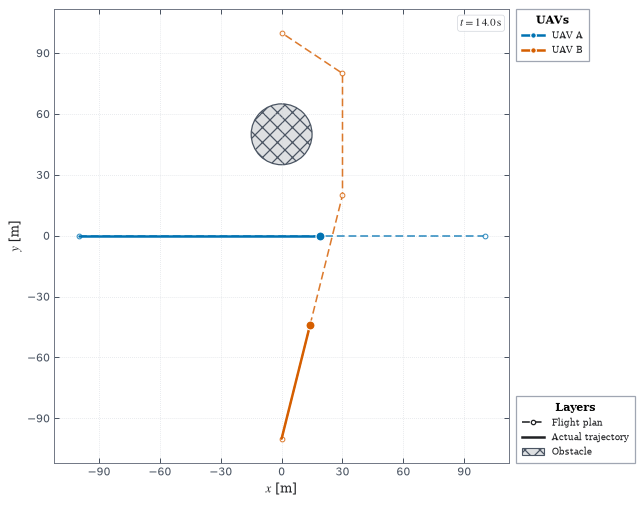

In [8]:
figure = plot_dataset(
    QUICKSTART_DATASET,
    config=VisualizationConfig(view="xy", show_flight_plans=True,
                               spatial_unit="m"),
    timestamp=14.0,
    output_path=FIGURES / "quickstart_xy.pdf",
)

## 9. Tactical layer and a dynamic geofence

A new scenario without strategic deconfliction: a geofence appears ahead of the UAS during the flight.

In [9]:
from musas.airspace import Geofence
from musas.algorithms import (
    FlightPlanAwareTracking,
    HybridGeometricManeuver,
    MinimumSeparationTacticalConflictPrediction,
)

TACTICAL_DATASET = OUTPUTS / "tactical.sqlite"

tactical_predictor = MinimumSeparationTacticalConflictPrediction(
    minimum_separation_distance=30.0, maximum_time_difference=0.25,
)
tactical_simulation = Simulation(
    airspace=Airspace(),
    # no strategic layer: both strategic algorithms are omitted
    tracking_algorithm=FlightPlanAwareTracking(),
    tactical_conflict_prediction_algorithm=tactical_predictor,
    tactical_deconfliction_algorithm=HybridGeometricManeuver(
        conflict_prediction_algorithm=tactical_predictor,
        minimum_separation_distance=30.0,
        airspace_clearance=15.0,
        maneuver_duration=4.0,
        maximum_speed=15.0,
        cooldown=2.0,
    ),
    report_interval=0.25,
    prediction_horizon=24,          # 24 states x 0.25 s = 6 s ahead
    prediction_step=0.25,
    tactical_assessment_interval=0.25,
    dataset_path=TACTICAL_DATASET,
    overwrite_dataset=True,
)

# A no-fly zone appears 40 m ahead of the UAV while it is flying.
tactical_simulation.schedule_geofence(
    Geofence(
        geofence_id="temporary-area",
        geometry=Cylinder3D(20.0, 0.0, 20.0, 0.0, 200.0),
    ),
    activation_time=10.0,
)
tactical_simulation.add_uav(
    name="UAV C",
    flight_plan=FlightPlan([
        Waypoint(-120.0, 0.0, 100.0, 2.0),
        Waypoint(120.0, 0.0, 100.0, 26.0),
    ]),
    dynamics_algorithm=FirstOrderDynamics(
        max_acceleration=100.0, velocity_time_constant=0.0,
    ),
    guidance_algorithm=WaypointGuidance(max_speed=15.0),
    waypoint_acceptance_radius=2.0,
)
tactical_result = tactical_simulation.run(until=45.0)
tactical_simulation.close()

## 10. Tactical results

t = 10.00 s  GEOFENCE_ACTIVATED
t = 10.00 s  TACTICAL_UPDATES_ISSUED
geofence violations: 0


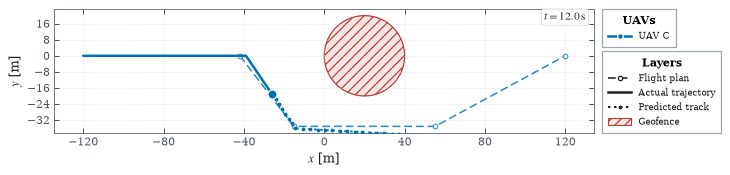

In [10]:
with SimulationDataset(TACTICAL_DATASET) as dataset:
    for event in dataset.get_events():
        if event.event in ("GEOFENCE_ACTIVATED", "TACTICAL_UPDATES_ISSUED"):
            print(f"t = {event.timestamp:5.2f} s  {event.event}")
    tactical_metrics = calculate_metrics(dataset, 30.0, 1.0)
print("geofence violations:", tactical_metrics["geofence_violations"])

figure = plot_dataset(
    TACTICAL_DATASET,
    config=VisualizationConfig(view="xy", show_flight_plans=True,
                               show_tracks=True, spatial_unit="m"),
    timestamp=12.0,
    output_path=FIGURES / "tactical_xy.pdf",
)

## 11. Plugging in your own algorithm

Any class that implements the contract can replace a built-in algorithm.

In [11]:
from musas.algorithms import StrategicDeconflictionAlgorithm
from musas.domain import StrategicDecision


class RejectOnConflict(StrategicDeconflictionAlgorithm):
    """Approve conflict-free proposals and reject all the others."""

    def deconflict(self, proposed_flight_plan, conflicts,
                   inactive_flight_plans, active_flight_plans, airspace):
        if conflicts:
            return StrategicDecision.REJECT, None, []
        return StrategicDecision.APPROVE, None, []


custom_simulation = Simulation(
    airspace=Airspace(),
    strategic_conflict_prediction_algorithm=strategic_predictor,
    strategic_deconfliction_algorithm=RejectOnConflict(),
)
for name, flight_plan in flight_plans.items():
    custom_simulation.add_uav(
        name=name,
        flight_plan=flight_plan,
        dynamics_algorithm=FirstOrderDynamics(),
        guidance_algorithm=WaypointGuidance(max_speed=15.0),
    )
custom_result = custom_simulation.run(until=40.0)
print({name: uav.status.name for name, uav in custom_result.uavs.items()})

{'UAV A': 'COMPLETED', 'UAV B': 'FLIGHT_PLAN_REJECTED'}


## 12. Reading the dataset

In [12]:
with SimulationDataset(QUICKSTART_DATASET) as dataset:
    print("UAVs:", dataset.uav_names)
    print("Run status:", dataset.run_status)

    # Strategic decisions taken for each proposal
    for event in dataset.get_events("STRATEGIC_DECISION_MADE"):
        print(f"t = {event.timestamp:.1f} s", event.details["summary"])

    # Recorded true states of one UAV
    samples = dataset.get_trajectory("UAV B", start_time=10.0, end_time=11.0)
    for sample in samples:
        print(f"t = {sample.timestamp:.1f} s",
              [round(value, 1) for value in sample.position])

UAVs: ('UAV A', 'UAV B')
Run status: COMPLETED
t = 0.0 s Strategic decision for UAV A: APPROVE
t = 0.0 s Strategic decision for UAV B: COUNTER_PROPOSAL
t = 10.2 s [4.3, -82.8, 100.0]
t = 10.4 s [4.8, -80.8, 100.0]
t = 10.6 s [5.3, -78.8, 100.0]
t = 10.8 s [5.8, -76.7, 100.0]
t = 11.0 s [6.3, -74.7, 100.0]


## 13. Animation

The GIF is written to `outputs/quickstart.gif`.

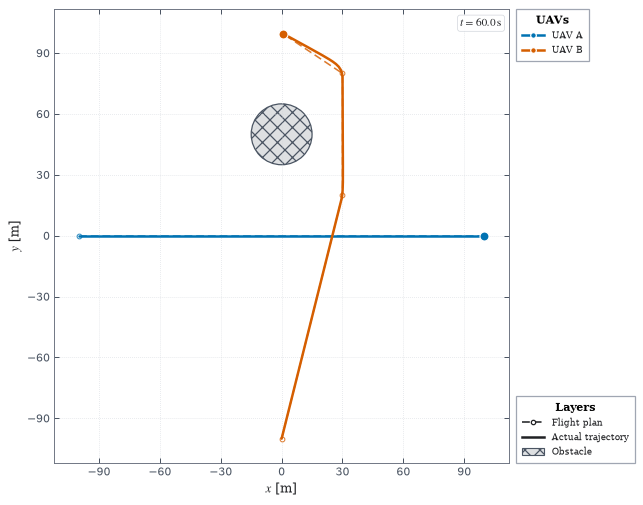

In [13]:
from musas.simulation import animate_dataset

animation = animate_dataset(
    QUICKSTART_DATASET,
    config=VisualizationConfig(view="xy", show_flight_plans=True,
                               frame_step=0.5, spatial_unit="m"),
    output_path=OUTPUTS / "quickstart.gif",
    fps=10,
)